# Phân cụm khách hàng sàn thương mại điện tử

Bài thực nghiệm giữa kỳ môn Phân tích và Khai phá dữ liệu.

- Mã sinh viên: 24022391 (a = 1, b = 4, c = 3)
- Số bản ghi: N = 220; số thuộc tính đầu vào: 12
- Số bản ghi ngoại lai chủ động tạo: tối thiểu 11

Notebook được chia theo các câu a–e và cần chạy tuần tự từ cell đầu tiên. Bộ sinh ngẫu nhiên được khởi tạo một lần với `np.random.default_rng(42)`, nên chạy lại toàn bộ notebook sẽ cho cùng dữ liệu.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
STUDENT_ID = "24022391"
N_CUSTOMERS = 220
N_INPUT_FEATURES = 12
MIN_OUTLIER_IDS = 11

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
METADATA_DIR = PROJECT_DIR / "metadata"
FIGURE_DIR = PROJECT_DIR / "figures"
RESULT_DIR = PROJECT_DIR / "results"
for directory in [DATA_DIR, METADATA_DIR, FIGURE_DIR, RESULT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
print("Project directory:", PROJECT_DIR)

Project directory: T:\Datamining-\customer_segmentation


## Câu a — Thiết kế và sinh dữ liệu

### a.1. Thiết kế thuộc tính

Mỗi bản ghi là một khách hàng, kèm `customer_id` dùng để định danh và đối chiếu giữa các phiên bản dữ liệu. `customer_id` không phải thuộc tính đầu vào của thuật toán. Đơn vị tiền tệ là **nghìn đồng**.

| Thuộc tính | Ý nghĩa | Kiểu | Lý do lựa chọn |
|---|---|---|---|
| `tenure_months` | Thời gian tham gia sàn (tháng) | int | Phân biệt khách lâu năm với khách mới |
| `recency_days` | Số ngày kể từ lần mua gần nhất | int | Thành phần R trong mô hình RFM, phản ánh mức độ còn hoạt động |
| `orders_6m` | Số đơn trong 6 tháng gần nhất | int | Thành phần F (tần suất mua) |
| `total_spend_6m` | Tổng chi tiêu 6 tháng | float | Thành phần M (giá trị tiền tệ) |
| `avg_order_value` | Giá trị đơn trung bình | float | Tách khách mua ít nhưng giá trị cao với khách mua nhiều đơn nhỏ |
| `sessions_30d` | Số phiên truy cập trong 30 ngày | int | Mức độ tương tác, không đồng nghĩa với mua hàng |
| `discount_usage_rate` | Tỷ lệ đơn có dùng mã giảm giá | float [0, 1] | Nhận diện mức nhạy cảm với khuyến mãi |
| `return_rate` | Tỷ lệ đơn bị hoàn trả | float [0, 1] | Chất lượng giao dịch, rủi ro vận hành |
| `category_diversity` | Số danh mục sản phẩm đã mua (1–8) | int | Độ rộng nhu cầu mua sắm |
| `cart_abandonment_rate` | Tỷ lệ giỏ hàng bị bỏ dở | float [0, 1] | Phân biệt khách chỉ xem với khách chuyển đổi thành đơn |
| `favorite_category` | Danh mục mua nhiều nhất | category (8 mức) | Đặc điểm sở thích, hỗ trợ diễn giải cụm |
| `preferred_device` | Thiết bị mua sắm chủ yếu | category (3 mức) | Hành vi kênh mua hàng |

In [2]:
NUMERIC_FEATURES = [
    "tenure_months", "recency_days", "orders_6m", "total_spend_6m",
    "avg_order_value", "sessions_30d", "discount_usage_rate", "return_rate",
    "category_diversity", "cart_abandonment_rate",
]
CATEGORICAL_FEATURES = ["favorite_category", "preferred_device"]
INPUT_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
COUNT_FEATURES = ["tenure_months", "recency_days", "orders_6m", "sessions_30d", "category_diversity"]
RATE_FEATURES = ["discount_usage_rate", "return_rate", "cart_abandonment_rate"]

CATEGORIES = [
    "Fashion", "Electronics", "Home & Living", "Beauty & Health",
    "Groceries", "Sports & Outdoor", "Books & Stationery", "Mother & Baby",
]
DEVICES = ["Mobile App", "Mobile Web", "Desktop"]

assert len(INPUT_FEATURES) == N_INPUT_FEATURES

### a.2. Cơ chế sinh dữ liệu

Dữ liệu được sinh từ bốn nhóm hành vi tiềm ẩn. Mỗi nhóm có bộ tham số phân phối riêng, nhưng các phân phối được chọn đủ rộng để các nhóm giao thoa nhau:

| Nhóm | Số khách | Đặc trưng chính |
|---|---|---|
| Loyal | 55 | Nhiều đơn, giá trị đơn cao, recency thấp, ít bỏ giỏ |
| Discount Seeker | 60 | Tỷ lệ dùng giảm giá cao, giá trị đơn thấp hơn, chi tiêu vừa phải |
| Browser | 55 | Truy cập nhiều, ít đơn, tỷ lệ bỏ giỏ cao |
| Inactive | 50 | Ít truy cập, ít đơn, recency cao |

Phân phối sử dụng:

- `tenure_months`: Normal, làm tròn và cắt trong [1, 120].
- `orders_6m` = 1 + Poisson(λ theo nhóm).
- `avg_order_value`: Lognormal, vì giá trị tiền tệ thường lệch phải.
- `sessions_30d`: Poisson với cường độ nhân thêm hệ số Gamma(3, 1/3), tức phân phối Negative Binomial. Hệ số này tạo khác biệt giữa các cá nhân trong cùng nhóm, làm các nhóm chồng lấn hơn.
- `recency_days`: Exponential với thang đo 180 / (orders_6m + 1) × hệ số nhóm. Khách mua nhiều thì lần mua gần nhất có xu hướng gần hơn.
- Các tỷ lệ: Beta, nên luôn nằm trong [0, 1].
- `category_diversity` = 1 + Poisson, cắt tối đa 8 (số danh mục của sàn).
- Hai biến phân loại: phân phối categorical với xác suất khác nhau theo nhóm.

Quy ước đơn giản hóa để dữ liệu nhất quán logic:

1. Tập khách hàng chỉ gồm khách có ít nhất 1 đơn trong 6 tháng, nên `orders_6m ≥ 1` và `recency_days ≤ 180`. Nhờ vậy `avg_order_value` luôn xác định.
2. `total_spend_6m = orders_6m × avg_order_value` (định nghĩa của giá trị đơn trung bình).
3. `recency_days ≤ 30 × tenure_months`: không thể mua trước khi tham gia sàn.
4. Nếu `recency_days ≤ 30` thì `sessions_30d ≥ 1`: có mua trong 30 ngày thì phải có ít nhất một phiên truy cập.
5. Các tỷ lệ được sinh như xu hướng hành vi liên tục, không suy ra từ số đơn rời rạc. Với khách chỉ có 1–2 đơn, tỷ lệ thực tế sẽ thô hơn.

Nhãn `true_segment` chỉ được lưu trong metadata để kiểm chứng giả lập. Nhãn này không nằm trong dữ liệu đầu vào và không được dùng ở bước tiền xử lý hay chọn mô hình.

In [3]:
SEGMENT_SIZES = {"Loyal": 55, "Discount Seeker": 60, "Browser": 55, "Inactive": 50}

# Xác suất danh mục theo thứ tự CATEGORIES; xác suất thiết bị theo thứ tự DEVICES.
SEGMENT_PARAMS = {
    "Loyal": dict(
        tenure=(36, 14), extra_orders=11.0, aov_median=650, aov_sigma=0.35,
        recency_factor=0.8, session_rate=16, discount_beta=(2, 6), return_beta=(1.5, 18),
        extra_categories=3.5, cart_beta=(2, 7),
        category_probs=[0.15, 0.20, 0.18, 0.12, 0.15, 0.08, 0.06, 0.06],
        device_probs=[0.60, 0.15, 0.25],
    ),
    "Discount Seeker": dict(
        tenure=(22, 12), extra_orders=6.0, aov_median=380, aov_sigma=0.35,
        recency_factor=1.0, session_rate=14, discount_beta=(7, 3), return_beta=(2, 12),
        extra_categories=2.5, cart_beta=(4, 5),
        category_probs=[0.25, 0.08, 0.12, 0.20, 0.18, 0.07, 0.04, 0.06],
        device_probs=[0.55, 0.30, 0.15],
    ),
    "Browser": dict(
        tenure=(15, 10), extra_orders=1.5, aov_median=450, aov_sigma=0.45,
        recency_factor=1.2, session_rate=24, discount_beta=(3, 5), return_beta=(2, 10),
        extra_categories=1.2, cart_beta=(7, 3),
        category_probs=[0.22, 0.25, 0.10, 0.12, 0.05, 0.12, 0.09, 0.05],
        device_probs=[0.35, 0.35, 0.30],
    ),
    "Inactive": dict(
        tenure=(24, 16), extra_orders=0.4, aov_median=400, aov_sigma=0.50,
        recency_factor=1.4, session_rate=4, discount_beta=(2, 4), return_beta=(1.5, 12),
        extra_categories=0.4, cart_beta=(4, 4),
        category_probs=[0.18, 0.14, 0.14, 0.12, 0.12, 0.10, 0.10, 0.10],
        device_probs=[0.30, 0.40, 0.30],
    ),
}

assert sum(SEGMENT_SIZES.values()) == N_CUSTOMERS
for params in SEGMENT_PARAMS.values():
    assert np.isclose(sum(params["category_probs"]), 1) and np.isclose(sum(params["device_probs"]), 1)

In [4]:
def generate_segment(size, params, rng):
    # Sinh khách hàng của một nhóm tiềm ẩn theo bộ tham số của nhóm đó.
    tenure = np.clip(np.round(rng.normal(*params["tenure"], size)), 1, 120).astype(int)
    orders = 1 + rng.poisson(params["extra_orders"], size)
    avg_order_value = rng.lognormal(np.log(params["aov_median"]), params["aov_sigma"], size).round(2)
    total_spend = (orders * avg_order_value).round(2)

    recency_scale = 180 / (orders + 1) * params["recency_factor"]
    recency = np.clip(np.round(rng.exponential(recency_scale)), 0, 180).astype(int)
    recency = np.minimum(recency, 30 * tenure)

    # Gamma-Poisson: mỗi khách có cường độ truy cập riêng quanh mức trung bình của nhóm.
    session_intensity = params["session_rate"] * rng.gamma(3.0, 1 / 3.0, size)
    sessions = rng.poisson(session_intensity)
    sessions = np.where(recency <= 30, np.maximum(sessions, 1), sessions)

    return pd.DataFrame({
        "tenure_months": tenure,
        "recency_days": recency,
        "orders_6m": orders,
        "total_spend_6m": total_spend,
        "avg_order_value": avg_order_value,
        "sessions_30d": sessions,
        "discount_usage_rate": rng.beta(*params["discount_beta"], size).round(3),
        "return_rate": rng.beta(*params["return_beta"], size).round(3),
        "category_diversity": np.minimum(1 + rng.poisson(params["extra_categories"], size), len(CATEGORIES)),
        "cart_abandonment_rate": rng.beta(*params["cart_beta"], size).round(3),
        "favorite_category": rng.choice(CATEGORIES, size, p=params["category_probs"]),
        "preferred_device": rng.choice(DEVICES, size, p=params["device_probs"]),
    })


def generate_clean_customers(rng):
    parts = []
    for segment, size in SEGMENT_SIZES.items():
        part = generate_segment(size, SEGMENT_PARAMS[segment], rng)
        part.insert(0, "true_segment", segment)
        parts.append(part)
    customers = pd.concat(parts, ignore_index=True)
    # Xáo trộn để thứ tự bản ghi không lộ nhóm tiềm ẩn.
    customers = customers.iloc[rng.permutation(len(customers))].reset_index(drop=True)
    customers.insert(0, "customer_id", [f"C{i:04d}" for i in range(1, len(customers) + 1)])
    return customers

In [5]:
rng = np.random.default_rng(SEED)

simulated = generate_clean_customers(rng)
customers_original = simulated[["customer_id"] + INPUT_FEATURES].copy()
segment_labels = simulated[["customer_id", "true_segment"]].copy()

print(customers_original.shape)
customers_original.head()

(220, 13)


,customer_id,tenure_months,recency_days,orders_6m,total_spend_6m,avg_order_value,sessions_30d,discount_usage_rate,return_rate,category_diversity,cart_abandonment_rate,favorite_category,preferred_device
0,C0001,1,30,2,895.20,447.60,18,0.789,0.147,1,0.317,Home & Living,Mobile App
1,C0002,39,3,11,5814.60,528.60,6,0.333,0.017,4,0.129,Electronics,Mobile App
2,C0003,40,122,1,388.01,388.01,40,0.184,0.240,1,0.834,Sports & Outdoor,Desktop
3,C0004,45,24,18,9305.82,516.99,15,0.188,0.002,4,0.308,Electronics,Mobile App
4,C0005,53,2,14,6774.32,483.88,12,0.385,0.026,3,0.299,Beauty & Health,Mobile App


In [6]:
def check_clean_data(df):
    # Kiểm tra các ràng buộc logic của dữ liệu sạch.
    assert len(df) == N_CUSTOMERS
    assert df["customer_id"].is_unique
    assert [c for c in df.columns if c != "customer_id"] == INPUT_FEATURES
    assert not df[INPUT_FEATURES].isna().any().any()
    for col in COUNT_FEATURES:
        assert pd.api.types.is_integer_dtype(df[col]) and (df[col] >= 0).all(), col
    for col in RATE_FEATURES:
        assert df[col].between(0, 1).all(), col
    assert (df["orders_6m"] >= 1).all() and (df["recency_days"] <= 180).all()
    assert np.allclose(df["total_spend_6m"], df["orders_6m"] * df["avg_order_value"], atol=0.01)
    assert (df["recency_days"] <= 30 * df["tenure_months"]).all()
    assert (df.loc[df["recency_days"] <= 30, "sessions_30d"] >= 1).all()
    assert df["category_diversity"].between(1, len(CATEGORIES)).all()
    assert set(df["favorite_category"]) <= set(CATEGORIES) and set(df["preferred_device"]) <= set(DEVICES)
    print(f"Clean data OK: {len(df)} records, {len(INPUT_FEATURES)} input features")


check_clean_data(customers_original)
customers_original[NUMERIC_FEATURES].describe().T.round(2)

Clean data OK: 220 records, 12 input features


,count,mean,std,min,25%,50%,75%,max
tenure_months,220.0,24.75,14.20,1.00,14.00,24.00,36.00,66.00
recency_days,220.0,39.16,48.21,0.00,7.00,21.00,45.25,180.00
orders_6m,220.0,5.85,4.77,1.00,2.00,4.00,9.00,19.00
total_spend_6m,220.0,3287.77,3610.79,95.26,779.96,1935.90,4541.03,18834.70
avg_order_value,220.0,512.62,260.90,95.26,359.12,437.36,614.47,1789.31
sessions_30d,220.0,14.95,12.88,0.00,5.00,12.00,20.25,86.00
discount_usage_rate,220.0,0.43,0.24,0.01,0.24,0.41,0.60,0.97
return_rate,220.0,0.12,0.09,0.00,0.05,0.10,0.17,0.45
category_diversity,220.0,2.73,1.77,1.00,1.00,2.00,4.00,8.00
cart_abandonment_rate,220.0,0.48,0.22,0.03,0.31,0.46,0.66,0.98


**Kiểm chứng giả lập (dùng nhãn tiềm ẩn).** Bảng trung bình theo nhóm và biểu đồ hộp dưới đây chỉ dùng để xác nhận cơ chế sinh dữ liệu hoạt động đúng thiết kế, tức các nhóm khác nhau theo hướng dự kiến nhưng vẫn chồng lấn. Kết quả này không được dùng ở các bước sau.

In [7]:
segment_view = customers_original.merge(segment_labels, on="customer_id")
segment_view.groupby("true_segment")[NUMERIC_FEATURES].mean().round(2).T

true_segment,Browser,Discount Seeker,Inactive,Loyal
tenure_months,16.20,22.67,23.38,36.84
recency_days,49.85,21.62,80.86,9.71
orders_6m,2.51,6.82,1.20,12.36
total_spend_6m,1305.70,2737.28,578.26,8333.57
avg_order_value,494.76,406.51,474.39,681.00
sessions_30d,25.45,13.02,4.00,16.49
discount_usage_rate,0.40,0.71,0.33,0.25
return_rate,0.17,0.14,0.11,0.07
category_diversity,2.04,3.12,1.28,4.31
cart_abandonment_rate,0.70,0.47,0.49,0.27


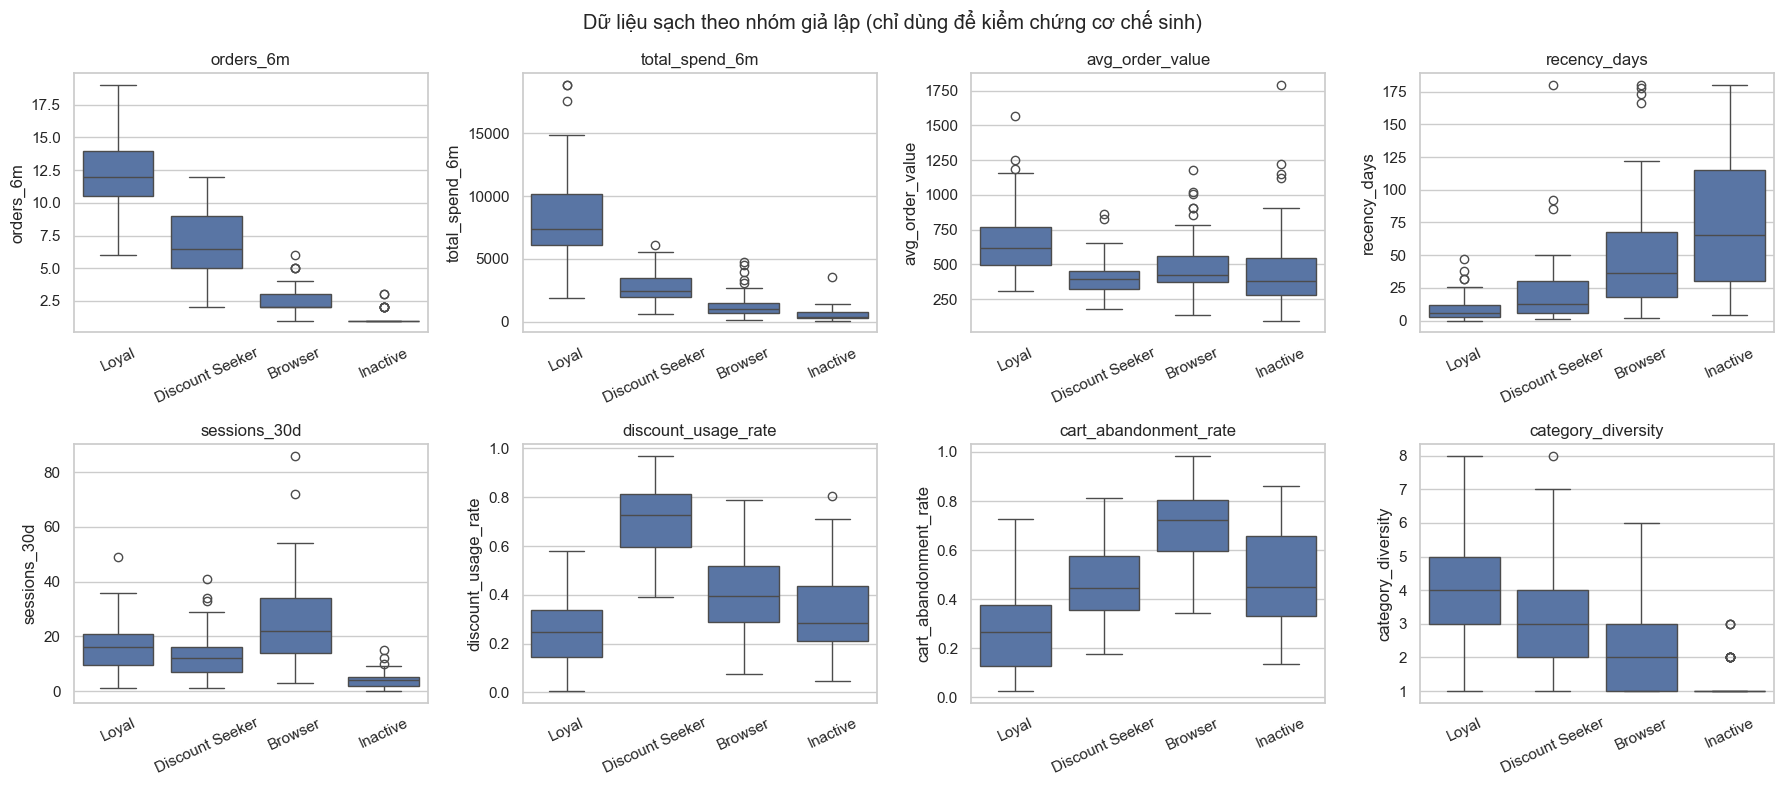

In [8]:
plot_features = [
    "orders_6m", "total_spend_6m", "avg_order_value", "recency_days",
    "sessions_30d", "discount_usage_rate", "cart_abandonment_rate", "category_diversity",
]
segment_order = list(SEGMENT_SIZES)

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), plot_features):
    sns.boxplot(data=segment_view, x="true_segment", y=col, order=segment_order, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle("Dữ liệu sạch theo nhóm giả lập (chỉ dùng để kiểm chứng cơ chế sinh)")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "a_clean_features_by_segment.png", dpi=150)
plt.show()

Để đánh giá định lượng mức giao thoa, tính silhouette của **nhãn giả lập** trên 10 thuộc tính số đã chuẩn hóa. Giá trị gần 1 cho thấy các nhóm tách biệt rõ, tức dữ liệu quá dễ phân cụm. Giá trị gần 0 cho thấy các nhóm chồng lấn mạnh. Chỉ số này chỉ dùng để mô tả dữ liệu giả lập.

In [9]:
scaled_clean_numeric = StandardScaler().fit_transform(customers_original[NUMERIC_FEATURES])
true_label_silhouette = silhouette_score(scaled_clean_numeric, segment_view["true_segment"])
print(f"Silhouette of simulated segments (clean, standardized numeric features): {true_label_silhouette:.3f}")

Silhouette of simulated segments (clean, standardized numeric features): 0.177


**Nhận xét.** Trung bình theo nhóm thay đổi theo đúng hướng đã thiết kế:

- Loyal có số đơn (12.36), chi tiêu (8333.57) và giá trị đơn (681.00) cao nhất, recency thấp nhất (9.71 ngày).
- Discount Seeker có `discount_usage_rate` cao nhất (0.71).
- Browser có số phiên cao nhất (25.45) nhưng chỉ 2.51 đơn, và tỷ lệ bỏ giỏ cao nhất (0.70).
- Inactive có số phiên (4.00) và số đơn (1.20) thấp nhất, recency cao nhất (80.86 ngày).

Biểu đồ hộp cho thấy nhiều biến chồng lấn đáng kể giữa các nhóm, đặc biệt `avg_order_value`, `return_rate` và `sessions_30d` giữa Loyal và Discount Seeker. Silhouette của nhãn giả lập là 0.177, tức các nhóm có cấu trúc nhưng không tách biệt rõ. Mức này phù hợp yêu cầu tránh dữ liệu quá dễ phân cụm.

### a.3. Đưa vào các vấn đề chất lượng dữ liệu

Thứ tự can thiệp trên bản sao `customers_corrupted`:

1. **Chọn bản ghi ngoại lai trước** (12 `customer_id`), sau đó loại các bản ghi này khỏi tập ứng viên của nhiễu và giá trị thiếu. Mỗi bản ghi ngoại lai vì thế chỉ chịu đúng một loại can thiệp, nên việc đối chiếu và đánh giá khả năng phát hiện không bị lẫn.
2. **Thêm nhiễu Gaussian** vào `total_spend_6m` và `sessions_30d`.
3. **Áp dụng ngoại lai.**
4. **Tạo giá trị thiếu** cho `avg_order_value` (MCAR) và `cart_abandonment_rate` (MAR).

Mọi can thiệp được ghi vào `simulation_metadata`.

#### Nhiễu Gaussian

Độ lớn nhiễu được chọn theo thang đo và dạng phân phối của từng biến:

- `total_spend_6m` lệch phải mạnh (từ vài trăm đến hàng chục nghìn). Một độ lệch chuẩn tuyệt đối chung sẽ làm khách chi tiêu thấp bị biến dạng rất mạnh, thậm chí ra giá trị âm. Vì vậy dùng nhiễu Gaussian **tương đối**: `x' = x · (1 + ε)`, với ε ~ N(0, 0.15²). Độ lệch chuẩn tuyệt đối của nhiễu tỷ lệ với giá trị gốc, tương ứng sai số ghi nhận hoặc quy đổi doanh thu.
- `sessions_30d` có thang đo hẹp: dùng nhiễu cộng `x' = x + ε`, với ε ~ N(0, (0.25 · σ_sessions)²), trong đó σ_sessions là độ lệch chuẩn của biến trên dữ liệu sạch. Kết quả làm tròn về số nguyên và cắt dưới tại 0 vì đây là biến đếm.

Mỗi biến được thêm nhiễu trên 40% số bản ghi. Các bản ghi được chọn ngẫu nhiên, độc lập giữa hai biến.

In [10]:
OUTLIER_BUSINESS_COUNT = 5
OUTLIER_ERROR_COUNT = 7
NOISE_FRACTION = 0.40
SPEND_RELATIVE_NOISE_SD = 0.15
SESSIONS_NOISE_SD_RATIO = 0.25
MISSING_AOV_RATE = 0.07    # MCAR
MISSING_CART_RATE = 0.08   # MAR theo sessions_30d


def select_outlier_ids(segment_labels, rng):
    # Ngoại lai nghiệp vụ lấy từ nhóm Loyal (khách VIP có thật); ngoại lai lỗi lấy ngẫu nhiên từ phần còn lại.
    loyal_ids = segment_labels.loc[segment_labels["true_segment"] == "Loyal", "customer_id"].to_numpy()
    business_ids = rng.choice(loyal_ids, OUTLIER_BUSINESS_COUNT, replace=False)
    remaining_ids = np.setdiff1d(segment_labels["customer_id"].to_numpy(), business_ids)
    error_ids = rng.choice(remaining_ids, OUTLIER_ERROR_COUNT, replace=False)
    return list(business_ids), list(error_ids)


def add_gaussian_noise(df, eligible_ids, rng):
    # Trả về bản dữ liệu đã thêm nhiễu và bảng log nhiễu theo từng bản ghi.
    noisy = df.copy()
    n_noisy = round(NOISE_FRACTION * len(df))
    logs = []

    spend_ids = rng.choice(eligible_ids, n_noisy, replace=False)
    mask = noisy["customer_id"].isin(spend_ids)
    before = noisy.loc[mask, "total_spend_6m"]
    epsilon = rng.normal(0, SPEND_RELATIVE_NOISE_SD, mask.sum())
    noisy.loc[mask, "total_spend_6m"] = np.maximum(before * (1 + epsilon), 0).round(2)
    logs.append(pd.DataFrame({"customer_id": noisy.loc[mask, "customer_id"], "column": "total_spend_6m",
                              "before": before, "after": noisy.loc[mask, "total_spend_6m"]}))

    sessions_sd = SESSIONS_NOISE_SD_RATIO * df["sessions_30d"].std()
    session_ids = rng.choice(eligible_ids, n_noisy, replace=False)
    mask = noisy["customer_id"].isin(session_ids)
    before = noisy.loc[mask, "sessions_30d"]
    noisy_values = np.maximum(np.round(before + rng.normal(0, sessions_sd, mask.sum())), 0)
    noisy.loc[mask, "sessions_30d"] = noisy_values.astype(int)
    logs.append(pd.DataFrame({"customer_id": noisy.loc[mask, "customer_id"], "column": "sessions_30d",
                              "before": before, "after": noisy.loc[mask, "sessions_30d"]}))

    noise_log = pd.concat(logs, ignore_index=True)
    noise_log["delta"] = noise_log["after"] - noise_log["before"]
    noise_params = {"total_spend_6m": f"relative N(0, {SPEND_RELATIVE_NOISE_SD}^2)",
                    "sessions_30d": f"additive N(0, {sessions_sd:.3f}^2)"}
    return noisy, noise_log, noise_params

#### Ngoại lai

Chọn 12 `customer_id` khác nhau (nhiều hơn mức tối thiểu 11):

- **5 ngoại lai hợp lệ về nghiệp vụ**, lấy từ nhóm Loyal. Giá trị vẫn tuân thủ các ràng buộc logic, ví dụ `total_spend_6m = orders_6m × avg_order_value` vẫn đúng:
  - 3 khách VIP chi tiêu lớn: `avg_order_value` nhân 4–6 lần.
  - 2 khách mua rất thường xuyên: 60–80 đơn trong 6 tháng, 60–90 phiên truy cập, recency 0–2 ngày.
- **7 ngoại lai do lỗi dữ liệu**, mỗi bản ghi vi phạm một ràng buộc:
  - 2 bản ghi lỗi đơn vị: `total_spend_6m` × 100.
  - 1 bản ghi lỗi tracking: `sessions_30d` = 999.
  - 1 bản ghi tỷ lệ vượt khoảng hợp lệ: `return_rate` = 1.85.
  - 1 bản ghi tỷ lệ âm: `discount_usage_rate` = −0.40.
  - 1 bản ghi giá trị âm: `tenure_months` = −12.
  - 1 bản ghi giá trị âm: `recency_days` = −15.

In [11]:
ERROR_RULES = [
    ("spend_unit_x100", "total_spend_6m"),
    ("spend_unit_x100", "total_spend_6m"),
    ("sessions_tracking_999", "sessions_30d"),
    ("return_rate_above_1", "return_rate"),
    ("discount_rate_negative", "discount_usage_rate"),
    ("tenure_negative", "tenure_months"),
    ("recency_negative", "recency_days"),
]


def apply_business_outliers(df, business_ids, rng):
    records = []
    for i, cid in enumerate(business_ids):
        idx = df.index[df["customer_id"] == cid][0]
        if i < 3:
            rule = "vip_high_order_value"
            df.loc[idx, "avg_order_value"] = round(df.loc[idx, "avg_order_value"] * rng.uniform(4, 6), 2)
            columns = ["avg_order_value", "total_spend_6m"]
        else:
            rule = "very_high_frequency"
            df.loc[idx, "orders_6m"] = rng.integers(60, 81)
            df.loc[idx, "sessions_30d"] = rng.integers(60, 91)
            df.loc[idx, "recency_days"] = rng.integers(0, 3)
            columns = ["orders_6m", "sessions_30d", "recency_days", "total_spend_6m"]
        # Giữ đúng định nghĩa tổng chi tiêu để ngoại lai vẫn hợp lệ về nghiệp vụ.
        df.loc[idx, "total_spend_6m"] = round(df.loc[idx, "orders_6m"] * df.loc[idx, "avg_order_value"], 2)
        records.append({"customer_id": cid, "outlier_type": "business_valid",
                        "outlier_rule": rule, "outlier_columns": ";".join(columns)})
    return records


def apply_error_outliers(df, error_ids):
    records = []
    for cid, (rule, column) in zip(error_ids, ERROR_RULES):
        idx = df.index[df["customer_id"] == cid][0]
        if rule == "spend_unit_x100":
            df.loc[idx, column] = round(df.loc[idx, column] * 100, 2)
        else:
            df.loc[idx, column] = {"sessions_tracking_999": 999, "return_rate_above_1": 1.85,
                                   "discount_rate_negative": -0.40, "tenure_negative": -12,
                                   "recency_negative": -15}[rule]
        records.append({"customer_id": cid, "outlier_type": "data_error",
                        "outlier_rule": rule, "outlier_columns": column})
    return records

#### Giá trị thiếu

- `avg_order_value`, **MCAR**: chọn ngẫu nhiên đều 7% số bản ghi (15 bản ghi). Việc thiếu không phụ thuộc vào bất kỳ giá trị nào.
- `cart_abandonment_rate`, **MAR**: 8% số bản ghi (18 bản ghi). Xác suất thiếu tỷ lệ với exp(−sessions_30d / 10), trong đó `sessions_30d` là giá trị quan sát được sau nhiễu. Giả định: khách ít truy cập có ít sự kiện giỏ hàng nên tỷ lệ bỏ giỏ khó được ghi nhận. Cơ chế thiếu phụ thuộc vào một biến quan sát được, không phụ thuộc vào chính giá trị bị thiếu hay nhãn nhóm.

In [12]:
def add_missing_values(df, eligible_ids, rng):
    eligible_mask = df["customer_id"].isin(eligible_ids)
    eligible = df.loc[eligible_mask]

    n_aov = round(MISSING_AOV_RATE * len(df))
    aov_ids = rng.choice(eligible["customer_id"].to_numpy(), n_aov, replace=False)

    n_cart = round(MISSING_CART_RATE * len(df))
    weights = np.exp(-eligible["sessions_30d"].to_numpy() / 10)
    cart_ids = rng.choice(eligible["customer_id"].to_numpy(), n_cart, replace=False, p=weights / weights.sum())

    df.loc[df["customer_id"].isin(aov_ids), "avg_order_value"] = np.nan
    df.loc[df["customer_id"].isin(cart_ids), "cart_abandonment_rate"] = np.nan
    return set(aov_ids), set(cart_ids)

In [13]:
business_ids, error_ids = select_outlier_ids(segment_labels, rng)
outlier_ids = business_ids + error_ids
non_outlier_ids = np.setdiff1d(customers_original["customer_id"].to_numpy(), outlier_ids)

customers_corrupted, noise_log, noise_params = add_gaussian_noise(customers_original, non_outlier_ids, rng)
outlier_records = apply_business_outliers(customers_corrupted, business_ids, rng)
outlier_records += apply_error_outliers(customers_corrupted, error_ids)
missing_aov_ids, missing_cart_ids = add_missing_values(customers_corrupted, non_outlier_ids, rng)

print("Noise parameters:", noise_params)
print("Outlier ids:", outlier_ids)

Noise parameters: {'total_spend_6m': 'relative N(0, 0.15^2)', 'sessions_30d': 'additive N(0, 3.219^2)'}
Outlier ids: ['C0197', 'C0129', 'C0118', 'C0077', 'C0133', 'C0143', 'C0146', 'C0137', 'C0127', 'C0013', 'C0192', 'C0131']


In [14]:
def build_simulation_metadata():
    meta = segment_labels.copy()
    for column, flag in [("total_spend_6m", "noise_total_spend"), ("sessions_30d", "noise_sessions")]:
        deltas = noise_log.loc[noise_log["column"] == column].set_index("customer_id")["delta"]
        meta[flag] = meta["customer_id"].isin(deltas.index)
        meta[f"{flag}_delta"] = meta["customer_id"].map(deltas).fillna(0.0)

    outlier_table = pd.DataFrame(outlier_records)
    meta = meta.merge(outlier_table, on="customer_id", how="left")
    meta["is_outlier"] = meta["outlier_type"].notna()
    meta[["outlier_type", "outlier_rule", "outlier_columns"]] = (
        meta[["outlier_type", "outlier_rule", "outlier_columns"]].fillna("none"))

    meta["missing_avg_order_value"] = meta["customer_id"].isin(missing_aov_ids)
    meta["missing_cart_abandonment_rate"] = meta["customer_id"].isin(missing_cart_ids)

    def error_types(row):
        types = []
        if row["missing_avg_order_value"] or row["missing_cart_abandonment_rate"]:
            types.append("missing")
        if row["noise_total_spend"] or row["noise_sessions"]:
            types.append("noise")
        if row["is_outlier"]:
            types.append(f"outlier_{row['outlier_type']}")
        return ";".join(types) if types else "clean"

    meta["error_types"] = meta.apply(error_types, axis=1)
    return meta


simulation_metadata = build_simulation_metadata()
print(simulation_metadata["error_types"].value_counts().to_string())
simulation_metadata.head()

error_types
noise                     118
clean                      59
missing;noise              20
missing                    11
outlier_data_error          7
outlier_business_valid      5


,customer_id,true_segment,noise_total_spend,noise_total_spend_delta,noise_sessions,noise_sessions_delta,outlier_type,outlier_rule,outlier_columns,is_outlier,missing_avg_order_value,missing_cart_abandonment_rate,error_types
0,C0001,Discount Seeker,False,0.00,False,0.0,none,none,none,False,True,True,missing
1,C0002,Loyal,False,0.00,False,0.0,none,none,none,False,False,False,clean
2,C0003,Browser,True,-13.75,True,0.0,none,none,none,False,False,False,noise
3,C0004,Loyal,True,-632.60,True,-1.0,none,none,none,False,False,False,noise
4,C0005,Loyal,False,0.00,True,-4.0,none,none,none,False,False,False,noise


Kiểm tra cơ chế thiếu: với MCAR, `sessions_30d` của nhóm thiếu và không thiếu `avg_order_value` không nên khác nhau có hệ thống. Với MAR, nhóm thiếu `cart_abandonment_rate` dự kiến có `sessions_30d` thấp hơn.

In [15]:
missing_mechanism_check = pd.DataFrame({
    column: customers_corrupted.groupby(customers_corrupted[column].isna())["sessions_30d"].median()
    for column in ["avg_order_value", "cart_abandonment_rate"]
}).rename(index={False: "observed", True: "missing"})
missing_mechanism_check.index.name = "median sessions_30d when value is"
missing_mechanism_check

,avg_order_value,cart_abandonment_rate
median sessions_30d when value is,,
observed,12.0,13.5
missing,11.0,4.5


**Nhận xét.**

- `avg_order_value` (MCAR): median `sessions_30d` của nhóm thiếu và nhóm quan sát được gần nhau (11 so với 12).
- `cart_abandonment_rate` (MAR): median `sessions_30d` của nhóm thiếu chỉ là 4.5, so với 13.5 ở nhóm quan sát được. Như vậy cơ chế thiếu phụ thuộc vào một biến quan sát được, đúng thiết kế.

Hệ quả cho tiền xử lý: điền `cart_abandonment_rate` bằng trung vị toàn cục có thể lệch, vì các bản ghi thiếu tập trung ở khách ít truy cập. Cần cân nhắc phương pháp điền có sử dụng biến quan sát khác.

Về phân bố can thiệp: 59 bản ghi không bị can thiệp, 118 bản ghi chỉ có nhiễu, 11 bản ghi chỉ có giá trị thiếu, 20 bản ghi có cả nhiễu lẫn giá trị thiếu, và 12 bản ghi ngoại lai.

### a.4. Mức độ thay đổi do nhiễu và đối chiếu ngoại lai

In [16]:
noise_summary = noise_log.groupby("column").agg(
    n_records=("customer_id", "nunique"),
    mean_before=("before", "mean"),
    mean_after=("after", "mean"),
    mean_abs_delta=("delta", lambda d: d.abs().mean()),
    max_abs_delta=("delta", lambda d: d.abs().max()),
)
noise_summary["mean_abs_relative_change"] = noise_log.assign(
    rel=lambda t: (t["delta"] / t["before"].where(t["before"] != 0)).abs()
).groupby("column")["rel"].mean()
noise_summary["corr_before_after"] = noise_log.groupby("column")[["before", "after"]].apply(
    lambda t: t["before"].corr(t["after"]))
noise_summary["clean_std"] = [customers_original[c].std() for c in noise_summary.index]
noise_summary.round(3)

,n_records,mean_before,mean_after,mean_abs_delta,max_abs_delta,mean_abs_relative_change,corr_before_after,clean_std
column,,,,,,,,
sessions_30d,88,16.295,16.614,2.432,7.0,0.352,0.974,12.875
total_spend_6m,88,3366.682,3217.773,388.625,4528.8,0.100,0.982,3610.793


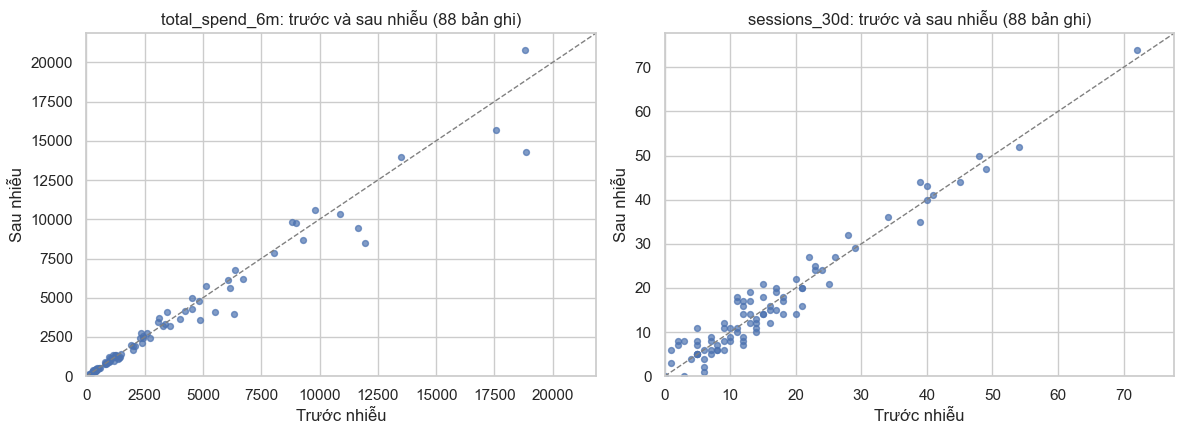

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, column in zip(axes, ["total_spend_6m", "sessions_30d"]):
    subset = noise_log[noise_log["column"] == column]
    ax.scatter(subset["before"], subset["after"], s=18, alpha=0.7)
    lim = [0, max(subset["before"].max(), subset["after"].max()) * 1.05]
    ax.plot(lim, lim, color="grey", linestyle="--", linewidth=1)
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    ax.set_title(f"{column}: trước và sau nhiễu ({len(subset)} bản ghi)")
    ax.set_xlabel("Trước nhiễu")
    ax.set_ylabel("Sau nhiễu")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "a_noise_before_after.png", dpi=150)
plt.show()

**Nhận xét.** Mỗi biến có 88 bản ghi bị tác động (40%):

- `total_spend_6m`: thay đổi tương đối trung bình khoảng 10%, tương quan trước/sau là 0.982. Độ lệch tuyệt đối lớn nhất (khoảng 4529) rơi vào khách chi tiêu cao, đúng với tính chất nhiễu tương đối.
- `sessions_30d`: thay đổi tuyệt đối trung bình 2.43 phiên. Thay đổi tương đối trung bình lên tới 35% vì nhiều khách chỉ có vài phiên. Có 74/88 bản ghi thực sự đổi giá trị; số còn lại có nhiễu bị làm tròn về 0 hoặc bị cắt tại 0.

Nhiễu làm giảm tính nhất quán `total_spend_6m = orders_6m × avg_order_value` ở các bản ghi bị tác động, nhưng chưa tạo ra giá trị cực đoan.

In [18]:
def outlier_comparison_table():
    rows = []
    for record in outlier_records:
        cid = record["customer_id"]
        for column in record["outlier_columns"].split(";"):
            rows.append({
                "customer_id": cid,
                "outlier_type": record["outlier_type"],
                "outlier_rule": record["outlier_rule"],
                "column": column,
                "original_value": customers_original.loc[customers_original["customer_id"] == cid, column].iloc[0],
                "corrupted_value": customers_corrupted.loc[customers_corrupted["customer_id"] == cid, column].iloc[0],
            })
    return pd.DataFrame(rows)


outlier_comparison = outlier_comparison_table()
outlier_comparison

,customer_id,outlier_type,outlier_rule,column,original_value,corrupted_value
0,C0197,business_valid,vip_high_order_value,avg_order_value,482.190,2803.41
1,C0197,business_valid,vip_high_order_value,total_spend_6m,6750.660,39247.74
2,C0129,business_valid,vip_high_order_value,avg_order_value,601.020,3027.50
3,C0129,business_valid,vip_high_order_value,total_spend_6m,7212.240,36330.00
4,C0118,business_valid,vip_high_order_value,avg_order_value,1084.070,6064.05
5,C0118,business_valid,vip_high_order_value,total_spend_6m,10840.700,60640.50
6,C0077,business_valid,very_high_frequency,orders_6m,12.000,63.00
7,C0077,business_valid,very_high_frequency,sessions_30d,14.000,85.00
8,C0077,business_valid,very_high_frequency,recency_days,5.000,2.00
9,C0077,business_valid,very_high_frequency,total_spend_6m,8778.240,46085.76


**Nhận xét.** 12 `customer_id` đã được can thiệp đúng như thiết kế.

- **Ngoại lai nghiệp vụ** có `total_spend_6m` từ khoảng 36 nghìn đến 80 nghìn, trong khi giá trị lớn nhất ở dữ liệu sạch là 18834.70. Chúng vẫn thỏa mọi ràng buộc logic, nên chỉ phương pháp thống kê (IQR, z-score, …) mới phát hiện được.
- **Ngoại lai lỗi** chia làm hai loại:
  - 4 bản ghi vi phạm miền giá trị (âm hoặc tỷ lệ > 1): có thể phát hiện bằng kiểm tra quy tắc nghiệp vụ.
  - 3 bản ghi có giá trị cực lớn (`total_spend_6m` × 100, `sessions_30d` = 999): vẫn hợp lệ về miền nhưng lệch rất xa phân phối.

Phần lớn ngoại lai lỗi chỉ lệch ở một cột, trong khi các cột còn lại bình thường. Do đó nếu chỉ kiểm tra từng biến riêng lẻ theo một phương pháp thống kê, một số bản ghi có thể không bị phát hiện. Khả năng phát hiện sẽ được đánh giá định lượng ở câu b.

### a.5. Kiểm tra tự động và lưu dữ liệu

In [19]:
def run_simulation_checks(original, corrupted, metadata):
    results = {}

    results["original_records"] = len(original)
    results["corrupted_records"] = len(corrupted)
    results["input_features"] = len([c for c in original.columns if c != "customer_id"])
    assert results["original_records"] == N_CUSTOMERS and results["corrupted_records"] == N_CUSTOMERS
    assert results["input_features"] == N_INPUT_FEATURES
    assert list(original.columns) == list(corrupted.columns)

    # Đối chiếu bằng customer_id: cùng tập id, không trùng lặp, cùng thứ tự.
    assert original["customer_id"].is_unique and corrupted["customer_id"].is_unique
    assert set(original["customer_id"]) == set(corrupted["customer_id"]) == set(metadata["customer_id"])
    assert (original["customer_id"].to_numpy() == corrupted["customer_id"].to_numpy()).all()

    assert original[INPUT_FEATURES].notna().all().all()
    missing_rate = corrupted[INPUT_FEATURES].isna().mean()
    missing_columns = missing_rate[missing_rate > 0]
    assert len(missing_columns) >= 2
    assert missing_columns.between(0.05, 0.10).all()
    results.update({f"missing_rate_{c}": round(r, 4) for c, r in missing_columns.items()})

    original_idx = original.set_index("customer_id")
    corrupted_idx = corrupted.set_index("customer_id")
    noisy_columns = []
    for column, flag in [("total_spend_6m", "noise_total_spend"), ("sessions_30d", "noise_sessions")]:
        noise_ids = metadata.loc[metadata[flag], "customer_id"]
        assert pd.api.types.is_numeric_dtype(corrupted[column])
        changed = (corrupted_idx.loc[noise_ids, column] != original_idx.loc[noise_ids, column]).sum()
        results[f"noise_records_{column}"] = len(noise_ids)
        results[f"noise_records_changed_{column}"] = int(changed)
        if changed > 0:
            noisy_columns.append(column)
    assert len(noisy_columns) >= 2

    outlier_meta = metadata[metadata["is_outlier"]]
    results["outlier_ids"] = outlier_meta["customer_id"].nunique()
    results["outlier_business_valid"] = int((outlier_meta["outlier_type"] == "business_valid").sum())
    results["outlier_data_error"] = int((outlier_meta["outlier_type"] == "data_error").sum())
    assert results["outlier_ids"] >= MIN_OUTLIER_IDS
    for _, row in outlier_meta.iterrows():
        for column in row["outlier_columns"].split(";"):
            assert original_idx.loc[row["customer_id"], column] != corrupted_idx.loc[row["customer_id"], column]

    # Bản ghi ngoại lai không chịu thêm nhiễu hay giá trị thiếu.
    other_flags = ["noise_total_spend", "noise_sessions", "missing_avg_order_value", "missing_cart_abandonment_rate"]
    assert not outlier_meta[other_flags].any().any()

    # Bản ghi không bị can thiệp phải giữ nguyên giá trị.
    clean_ids = metadata.loc[metadata["error_types"] == "clean", "customer_id"]
    assert original_idx.loc[clean_ids, INPUT_FEATURES].equals(corrupted_idx.loc[clean_ids, INPUT_FEATURES])
    results["untouched_records"] = len(clean_ids)

    assert "true_segment" not in corrupted.columns and "true_segment" not in original.columns
    return pd.Series(results, name="value", dtype=object).to_frame()


simulation_checks = run_simulation_checks(customers_original, customers_corrupted, simulation_metadata)
simulation_checks

,value
original_records,220
corrupted_records,220
input_features,12
missing_rate_avg_order_value,0.0682
missing_rate_cart_abandonment_rate,0.0818
noise_records_total_spend_6m,88
noise_records_changed_total_spend_6m,88
noise_records_sessions_30d,88
noise_records_changed_sessions_30d,74
outlier_ids,12


In [20]:
original_path = DATA_DIR / "customers_original.csv"
corrupted_path = DATA_DIR / "customers_corrupted.csv"
metadata_path = METADATA_DIR / "simulation_metadata.csv"

customers_original.to_csv(original_path, index=False)
customers_corrupted.to_csv(corrupted_path, index=False)
simulation_metadata.to_csv(metadata_path, index=False)

# Đọc lại từ đĩa để chắc chắn tệp lưu đúng và vẫn đối chiếu được.
reloaded_original = pd.read_csv(original_path)
reloaded_corrupted = pd.read_csv(corrupted_path)
reloaded_metadata = pd.read_csv(metadata_path)
run_simulation_checks(reloaded_original, reloaded_corrupted, reloaded_metadata)
for path in [original_path, corrupted_path, metadata_path]:
    print(f"Saved {path.relative_to(PROJECT_DIR)} ({path.stat().st_size} bytes)")

Saved data\customers_original.csv (16633 bytes)
Saved data\customers_corrupted.csv (16472 bytes)
Saved metadata\simulation_metadata.csv (18802 bytes)


### a.6. Giả định và hạn chế của dữ liệu giả lập

- **Phân bố do người thiết kế chọn.** Bốn nhóm và tham số phân phối dựa trên giả định hợp lý về hành vi mua sắm, không ước lượng từ dữ liệu thực. Cấu trúc cụm "đúng" vì vậy phản ánh giả định của mô phỏng.
- **Số nhóm cố định là 4**, kích thước gần cân bằng (50–60 khách). Dữ liệu thực thường mất cân bằng hơn, ví dụ khách không hoạt động chiếm đa số.
- **Quan hệ giữa các biến được đơn giản hóa**: tổng chi tiêu là tích chính xác của số đơn và giá trị đơn trung bình; recency chỉ phụ thuộc vào số đơn và hệ số nhóm; các tỷ lệ là xu hướng liên tục, độc lập với nhau khi đã biết nhóm.
- **Tập khách chỉ gồm khách có ít nhất 1 đơn trong 6 tháng**, nên không mô hình hóa khách đã rời bỏ hoàn toàn.
- **Biến phân loại phụ thuộc yếu vào nhóm**. Chúng chủ yếu hỗ trợ diễn giải cụm, khả năng phân biệt nhóm thấp.
- **Mẫu nhỏ (220 bản ghi)**: thống kê theo nhóm có phương sai lớn, kết quả có thể thay đổi đáng kể với seed khác.
- **Lỗi dữ liệu được tạo có chủ đích và tách bạch**: mỗi ngoại lai chỉ có một loại lỗi, không chồng với nhiễu hay giá trị thiếu. Trong dữ liệu thực, các loại lỗi thường đan xen và không có metadata để đối chiếu.
- **Cơ chế MAR cho `cart_abandonment_rate` dựa trên `sessions_30d` sau nhiễu**: giả định này hợp lý về nghiệp vụ nhưng chưa được kiểm chứng trên dữ liệu thực.